<a href="https://colab.research.google.com/github/antoine-bourgois/MIA_2026_UE16_NLP/blob/main/code/1_Exploration_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP 1 : Exploration Dataset

- Explorer HuggingFace
- Charger un Dataset
- Description du contenu du dataset
- Description statistique du dataset
- Analyse tokens vs lemmes
- Distribution des tokens
- Loi de Zipf

### HuggingFace, un acteur central en Traitement Automatique du Langage (TAL)

Visitez [Hugging Face](https://huggingface.co/) et prenez 5 minutes pour explorer les principaux onglets [`Models`](https://huggingface.co/models) et [`Datasets`](https://huggingface.co/datasets)

### Installation des librairies Python utiles pour le TP

In [1]:
!pip install tqdm jupyter ipywidgets datasets pyarrow huggingface_hub pandas matplotlib numpy --quiet


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
from tqdm.auto import tqdm

### Charger un jeu de données à partir de HugginFace

In [3]:
from datasets import load_dataset_builder

dataset_path = "AntoineBourgois/Gallica_Hors-d-Usage_cleaned"

builder = load_dataset_builder(dataset_path)

builder = load_dataset_builder(dataset_path,)

print(f"Le jeu de données {dataset_path!r} contient {len(builder.info.splits)} sous-ensembles :")
for name, split in builder.info.splits.items():
    print(f"    {name!r:<20}{split.num_examples:<6,} documents")

Le jeu de données 'AntoineBourgois/Gallica_Hors-d-Usage_cleaned' contient 5 sous-ensembles :
    'tous'              6,156  documents
    'auteur_genre'      200    documents
    'auteur'            200    documents
    'date_publication'  200    documents
    'genre_litteraire'  200    documents


Nous commençons par sélectionner l'un des 4 sous-ensembles de 200 documents.

In [4]:
# sous_ensemble, label_column = "auteur_genre", "auteur_genre"
# sous_ensemble, label_column = "auteur", "auteur"
sous_ensemble, label_column = "date_publication", "date_publication"
# sous_ensemble, label_column = "genre_litteraire", "genre_litteraire"

In [5]:
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

dataset_path = "AntoineBourgois/Gallica_Hors-d-Usage_cleaned"

fichier_local = hf_hub_download(
    repo_id=dataset_path,
    filename=f"data/{sous_ensemble}-00000-of-00001.parquet",
    repo_type="dataset",
    force_download=True,
)

table = pq.read_table(fichier_local)
dataset = table.to_pylist()

print("Nombre de documents :", len(dataset))

def conversions_string_vers_liste(string):
    if isinstance(string, str):
        return string.split(" ")

for document in dataset:
    document["tokens"] = conversions_string_vers_liste(document["tokens"])
    document["lemmes"] = conversions_string_vers_liste(document["lemmes"])

data/date_publication-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  178MB            

data/date_publication-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Nombre de documents : 200


### Structure du dataset

In [6]:
print(f"Type dataset: {type(dataset)}")
print(f"Longueur dataset: {len(dataset)}")

doc_0 = dataset[0]
print(f"Type 1er document: {type(doc_0)}")
print(f"Clés d'un document: {doc_0.keys()}")

Type dataset: <class 'list'>
Longueur dataset: 200
Type 1er document: <class 'dict'>
Clés d'un document: dict_keys(['doc_id', 'date_publication', 'titre', 'auteur', 'auteur_genre', 'auteur_nom', 'auteur_prenom', 'genre_litteraire', 'texte', 'tokens', 'lemmes'])


In [7]:
for key, value in doc_0.items():
    print(f"{key:<20} {type(value)}    {str(value)[:100]}")

doc_id               <class 'str'>    HDU-00027
date_publication     <class 'int'>    1801
titre                <class 'str'>    Atala, ou les Amours de deux sauvages dans le désert
auteur               <class 'str'>    François-René de Chateaubriand
auteur_genre         <class 'str'>    masculin
auteur_nom           <class 'str'>    Chateaubriand
auteur_prenom        <class 'str'>    François-René de
genre_litteraire     <class 'str'>    autre
texte                <class 'str'>    Ans sur cette quatrième Edition'. -S quelque temps, il a paru de nouvelles critiques d'Atala. Je n'a
tokens               <class 'list'>    ['Ans', 'sur', 'cette', 'quatrième', 'Edition', "'", '.', '-S', 'quelque', 'temps', ',', 'il', 'a', 
lemmes               <class 'list'>    ['an', 'sur', 'ce', 'quatrième', 'edition', "'", '.', '-s', 'quelque', 'temps', ',', 'il', 'avoir', 


In [8]:
all_publication_date = [doc["date_publication"] for doc in dataset]
print("Min Year\t:", min(all_publication_date))
print("Max Year\t:", max(all_publication_date))
print("Mean Year\t:", int(sum(all_publication_date)/len(all_publication_date)))

Min Year	: 1801
Max Year	: 1948
Mean Year	: 1874


In [9]:
from collections import Counter
all_authors = [doc["auteur"] for doc in dataset]
Counter(all_authors).most_common(10)

[('François-René de Chateaubriand', 1),
 ('Marie Armande Jeanne Gacon-Dufour', 1),
 ('Jakob Heinrich Meister', 1),
 ('Jean-Baptiste Pollin', 1),
 ('Pierre-Nicolas Rougeron', 1),
 ('Galart de Montjoie', 1),
 ('Henri-Louis Coiffier de Verfeu', 1),
 ('Henri-Sébastien Blaze', 1),
 ('Sophie de Renneville', 1),
 ('Joseph Senties', 1)]

In [10]:
all_authors_gender = [doc["auteur_genre"] for doc in dataset]
Counter(all_authors_gender).most_common()

[('masculin', 158), ('féminin', 42)]

In [11]:
all_genre = [doc["genre_litteraire"] for doc in dataset]
Counter(all_genre).most_common()

[('autre', 175), ('aventure', 16), ('detective', 9)]

### Vocabulaire

Construire un dictionnaire du vocabulaire du corpus.

In [12]:
all_tokens = [token
              for document in dataset
              for token in document["tokens"]
              ]
vocab = sorted(set(all_tokens))
print(f"Taille du corpus: {len(all_tokens):,} tokens")
print(f"Taille du vocabulaire: {len(vocab):,} tokens")

Taille du corpus: 19,719,426 tokens
Taille du vocabulaire: 348,436 tokens


In [13]:
import pandas as pd
from collections import Counter

vocab_counter = Counter(all_tokens).most_common()

df = pd.DataFrame([
    {
        "Rang": i + 1,
        "Token": word,
        "Occurrences": count,
        "Fréquence (%)": 100 * count / len(all_tokens)
    }
    for i, (word, count) in enumerate(vocab_counter)
])

In [14]:
N = 20
print(df.head(N).to_string(
    index=False,
    formatters={"Fréquence (%)": "{:.2f}%".format},
    justify="center"
))

 Rang Token  Occurrences Fréquence (%)
   1     ,    1337995        6.79%    
   2     .     693250        3.52%    
   3    de     689834        3.50%    
   4    la     388589        1.97%    
   5    et     364399        1.85%    
   6    le     317348        1.61%    
   7     à     315947        1.60%    
   8    l'     227186        1.15%    
   9   les     222049        1.13%    
  10   que     210849        1.07%    
  11    un     203084        1.03%    
  12    il     192641        0.98%    
  13    d'     177380        0.90%    
  14    en     172829        0.88%    
  15   une     148799        0.75%    
  16   qui     148772        0.75%    
  17    ne     138918        0.70%    
  18   des     138715        0.70%    
  19   pas     129723        0.66%    
  20   est     127865        0.65%    


In [15]:
target_words = ["homme", "femme", "roi", "reine", "chien", "chat", "cheval", "heureux", "malheureux"]
df[df["Token"].isin(target_words)]

,Rang,Token,Occurrences,Fréquence (%)
94,95,homme,22519,0.114197
103,104,femme,18796,0.095317
265,266,roi,6785,0.034408
429,430,heureux,4126,0.020924
544,545,malheureux,3062,0.015528
548,549,reine,3048,0.015457
582,583,cheval,2804,0.014219
1247,1248,chien,1244,0.006309
4063,4064,chat,358,0.001815


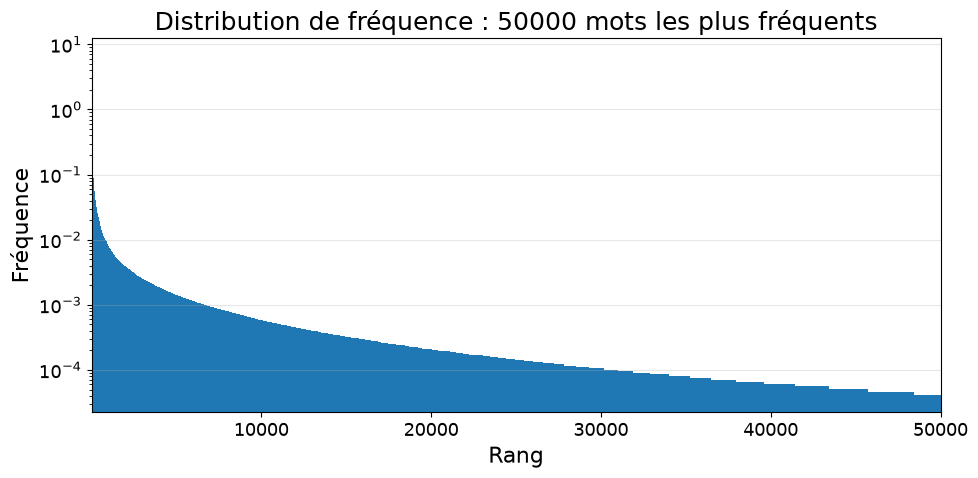

In [17]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# Global font settings
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 18,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
})

vocab_counter = Counter(all_tokens)

frequencies = sorted(vocab_counter.values(), reverse=True)

N = 50000
frequencies = [n * 100 / len(all_tokens) for n in frequencies[:N]]
ranks = np.arange(1, len(frequencies) + 1)

plt.figure(figsize=(10, 5))
plt.bar(ranks, frequencies, width=1.0)

plt.xlabel("Rang")
plt.ylabel("Fréquence")
plt.title(f"Distribution de fréquence : {N} mots les plus fréquents")

plt.xlim(1, N)
plt.grid(axis="y", alpha=0.3)
plt.yscale("log")
plt.tight_layout()
plt.show()

In [18]:
print(f"Vocabulaire : {len(vocab_counter):,}")
print(f"Mots apparaissant une seule fois : {sum(c == 1 for c in vocab_counter.values()):,}")
print(f"Mots apparaissant moins de 5 fois : {sum(c < 5 for c in vocab_counter.values()):,}")
print(f"Mots apparaissant moins de 20 fois : {sum(c < 20 for c in vocab_counter.values()):,}")
print(f"Mots apparaissant moins de 100 fois : {sum(c < 100 for c in vocab_counter.values()):,}")
print(f"Mots apparaissant moins de 1 000 fois : {sum(c < 1000 for c in vocab_counter.values()):,}")

Vocabulaire : 348,436
Mots apparaissant une seule fois : 212,833
Mots apparaissant moins de 5 fois : 281,439
Mots apparaissant moins de 20 fois : 317,438
Mots apparaissant moins de 100 fois : 337,358
Mots apparaissant moins de 1 000 fois : 346,909


### Loi de Zipf

La [loi de Zipf](https://fr.wikipedia.org/wiki/Loi_de_Zipf) est une observation empirique selon laquelle, dans de nombreux ensembles de données classés par ordre décroissant, la fréquence ou la taille d'un élément de rang n est inversement proportionnelle à n. Elle a été formulée en 1932 par le linguiste George Kingsley Zipf (1902-1950) à propos de la fréquence des mots dans un texte.

In [ ]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

# Global font settings
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 20,
    "axes.labelsize": 17,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14,
})

vocab_counter = Counter(all_tokens)
frequencies = np.array(sorted(vocab_counter.values(), reverse=True))
ranks = np.arange(1, len(frequencies) + 1)

# Log-transform
log_ranks = np.log(ranks)
log_freqs = np.log(frequencies)

# Fit a linear regression in log-log space
slope, intercept = np.polyfit(log_ranks, log_freqs, 1)

# Predicted values
fitted_freqs = np.exp(intercept) * ranks ** slope

# Plot
plt.figure(figsize=(10, 5))

plt.loglog(ranks, frequencies, label="Fréquences observées")
plt.loglog(
    ranks,
    fitted_freqs,
    "--",
    linewidth=2,
    label=f"Ajustement en loi de puissance (s={-slope:.3f})"
)

plt.xlabel("Rang")
plt.ylabel("Fréquence")
plt.title("Loi de Zipf dans le corpus")

plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Exposant de Zipf estimé : {-slope:.4f}")